# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [1]:
# Importy
import pickle
import time
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, GroupKFold, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RS = 42                                   # ziarno losowości: zawsze te same wyniki
pd.set_option("display.width", 200)

In [2]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data/zadanie-1/pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [3]:
# A1. Wczytanie oficjalnych plików train i test
# Każdy wiersz: 8 punktów śladu pióra (x1, y1, ..., x8, y8) i narysowana cyfra.
FOLDER = DATA_DIR / "pendigits"
cechy = [f"{os}{i}" for i in range(1, 9) for os in "xy"]
train = pd.read_csv(FOLDER / "pendigits.tra", names=cechy + ["cyfra"])
test = pd.read_csv(FOLDER / "pendigits.tes", names=cechy + ["cyfra"])
print("train:", train.shape, " test:", test.shape)


# Numer osoby, która pisała cyfrę, jest w plikach "orig" w liniach ".COMMENT cyfra osoba próbka".
def osoby(plik):
    return [int(linia.split()[2]) for linia in open(plik) if linia.startswith(".COMMENT")]


train["osoba"] = osoby(FOLDER / "pendigits-orig.tra")
test["osoba"] = osoby(FOLDER / "pendigits-orig.tes")
print("osoby w train:", train.osoba.nunique(), " w test:", test.osoba.nunique())

train: (7494, 17)  test: (3498, 17)
osoby w train: 30  w test: 14


braki: 0 0
duplikaty w train: 0  wspólne wiersze train i test: 0
cyfra
0    0.104
1    0.104
2    0.104
3    0.096
4    0.104
5    0.096
6    0.096
7    0.104
8    0.096
9    0.096
Name: proportion, dtype: float64
    min    max   std
x1  0.0  100.0  33.3
y1  0.0  100.0  16.8
x2  0.0  100.0  26.3
y2  0.0  100.0  19.6
x3  0.0  100.0  34.9
y3  0.0  100.0  27.4
x4  0.0  100.0  30.7
y4  0.0  100.0  30.7
x5  0.0  100.0  33.7
y5  0.0  100.0  27.5
x6  0.0  100.0  37.1
y6  0.0  100.0  27.5
x7  0.0  100.0  22.6
y7  0.0  100.0  33.2
x8  0.0  100.0  41.5
y8  0.0  100.0  35.8


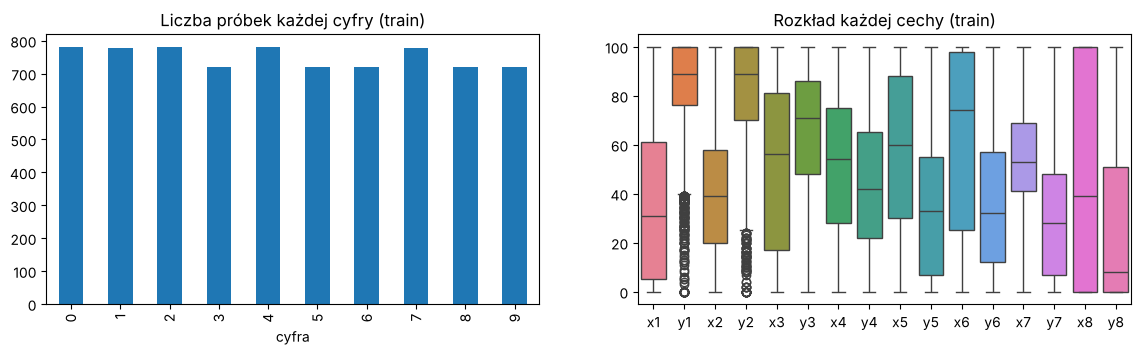

In [4]:
# A2. Braki, duplikaty, rozkład klas, zakresy
print("braki:", train.isna().sum().sum(), test.isna().sum().sum())
print("duplikaty w train:", train[cechy].duplicated().sum(), " wspólne wiersze train i test:",
      len(train[cechy].merge(test[cechy])))
print(train.cyfra.value_counts(normalize=True).sort_index().round(3))
print(train[cechy].describe().T[["min", "max", "std"]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
train.cyfra.value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Liczba próbek każdej cyfry (train)")
sns.boxplot(data=train[cechy], ax=axes[1]).set_title("Rozkład każdej cechy (train)")
plt.show()

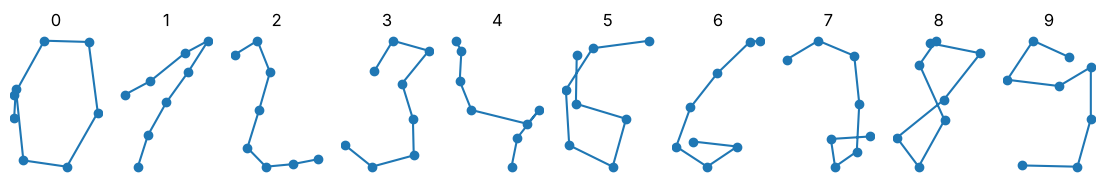

In [5]:
# A3. Przykładowa cyfra każdego rodzaju (cechy narysowane jako ślad pióra)
fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for cyfra, ax in enumerate(axes):
    w = train[train.cyfra == cyfra].iloc[0]
    ax.plot(w[cechy[0::2]].to_numpy(), w[cechy[1::2]].to_numpy(), "o-")
    ax.set_title(cyfra)
    ax.axis("off")
plt.show()

### Wnioski z eksploracji i preprocessing
- **Zmienna docelowa:** `cyfra` (0 do 9), czyli klasyfikacja z 10 klasami. **Cechy:** 16 liczb,
  współrzędne x i y ośmiu punktów śladu pióra, przeskalowane przez autorów do 0 do 100.
  Kolumna `osoba` nie jest cechą, służy tylko do podziału w walidacji (B).
- **Klasy** są prawie równe (9,6% do 10,4%), więc accuracy jest sensowna. Podaję też macro F1.
- **Braki i duplikaty:** brak, także między train i test. **Zakresy:** 0 do 100, bez błędnych wartości.
- **Podział:** oficjalny. Train napisało 30 osób, test 14 innych osób.
- **Preprocessing:** tylko `StandardScaler` dla modeli wrażliwych na skalę (regresja logistyczna,
  k-NN, SVM), bo cechy mają różny rozrzut (odchylenie 17 do 42). Skaler jest w pipeline,
  więc uczy się wyłącznie na danych treningowych.

## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [6]:
# B1. Walidacja: foldy według osób zamiast losowych
# W losowych foldach cyfry tej samej osoby są i w części uczącej, i sprawdzającej, a model zna
# już jej charakter pisma. Test pisały inne osoby, więc uczciwsze są foldy według osób (GroupKFold).
X_train, y_train, X_test, y_test = train[cechy], train.cyfra, test[cechy], test.cyfra
knn1 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1))
losowe = cross_val_score(knn1, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RS))
wg_osob = cross_val_score(knn1, X_train, y_train, cv=GroupKFold(5), groups=train.osoba)
print(f"k-NN (k=1): foldy losowe {losowe.mean():.4f}, foldy według osób {wg_osob.mean():.4f}")

k-NN (k=1): foldy losowe 0.9944, foldy według osób 0.9672


In [7]:
# B2. Kandydaci i strojenie (walidacja krzyżowa według osób, tylko train)
kandydaci = {   # nazwa: (model, siatka hiperparametrów)
    "Baseline": (DummyClassifier(), {}),
    "Naive Bayes": (GaussianNB(), {}),
    "Regresja logistyczna": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                             {"logisticregression__C": [0.1, 1, 10]}),
    "k-NN": (make_pipeline(StandardScaler(), KNeighborsClassifier()), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7]}),
    "SVM": (make_pipeline(StandardScaler(), SVC()), {"svc__C": [1, 10, 100]}),
    "Las losowy": (RandomForestClassifier(random_state=RS), {"n_estimators": [100, 300]}),
}
najlepsze, wynik_cv = {}, {}
for nazwa, (model, siatka) in kandydaci.items():
    gs = GridSearchCV(model, siatka, cv=GroupKFold(5)).fit(X_train, y_train, groups=train.osoba)
    najlepsze[nazwa], wynik_cv[nazwa] = gs.best_estimator_, gs.best_score_
    print(f"{nazwa:22s} CV accuracy {gs.best_score_:.4f}  {gs.best_params_}")

Baseline               CV accuracy 0.1041  {}
Naive Bayes            CV accuracy 0.8647  {}


Regresja logistyczna   CV accuracy 0.9365  {'logisticregression__C': 10}


k-NN                   CV accuracy 0.9681  {'kneighborsclassifier__n_neighbors': 3}


SVM                    CV accuracy 0.9777  {'svc__C': 10}


Las losowy             CV accuracy 0.9670  {'n_estimators': 300}


### Dobór modeli i ochrona przed wyciekiem
- **Baseline** (zawsze najczęstsza cyfra) to punkt odniesienia, około 10%.
- **Naive Bayes:** klasyfikator statystyczny, zakłada niezależne cechy.
- **Regresja logistyczna:** model liniowy. **k-NN:** głosowanie najbliższych sąsiadów.
  **SVM:** nieliniowe granice. **Las losowy:** wiele drzew decyzyjnych.
- Hiperparametry wybiera `GridSearchCV` walidacją krzyżową na train.
- **Wyciek:** skalowanie w pipeline, foldy według osób (pokaz w B1), test użyty tylko raz w C,
  brak wspólnych wierszy train i test.

## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [8]:
# C1. Wyniki na teście, czas i rozmiar modeli
wiersze, pred = [], {}
for nazwa, model in najlepsze.items():
    start = time.perf_counter(); model.fit(X_train, y_train); uczenie = time.perf_counter() - start
    start = time.perf_counter(); pred[nazwa] = model.predict(X_test); predykcja = time.perf_counter() - start
    wiersze.append({"model": nazwa, "CV accuracy": wynik_cv[nazwa],
                    "test accuracy": accuracy_score(y_test, pred[nazwa]),
                    "macro F1": f1_score(y_test, pred[nazwa], average="macro"),
                    "błędy": (pred[nazwa] != y_test).sum(), "uczenie [s]": uczenie, "predykcja [s]": predykcja,
                    "rozmiar [kB]": len(pickle.dumps(model)) / 1024})   # pickle zamienia model na bajty
wyniki = pd.DataFrame(wiersze).set_index("model").sort_values("test accuracy", ascending=False)
print(wyniki.round(4))

                      CV accuracy  test accuracy  macro F1  błędy  uczenie [s]  predykcja [s]  rozmiar [kB]
model                                                                                                      
SVM                        0.9777         0.9814    0.9814     65       0.1167         0.1291      171.0654
k-NN                       0.9681         0.9748    0.9750     88       0.0055         0.0606      996.9492
Las losowy                 0.9670         0.9646    0.9650    124       2.2422         0.0964    25590.1973
Regresja logistyczna       0.9365         0.9282    0.9285    251       0.1509         0.0024        2.9863
Naive Bayes                0.8647         0.8225    0.8173    621       0.0046         0.0065        3.4209
Baseline                   0.1041         0.1038    0.0188   3135       0.0010         0.0001        0.7461


Najlepszy model: SVM
              precision    recall  f1-score   support

           0      0.997     0.975     0.986       363
           1      0.973     0.986     0.980       364
           2      0.989     1.000     0.995       364
           3      0.965     0.991     0.978       336
           4      0.997     0.986     0.992       364
           5      0.979     0.985     0.982       335
           6      0.994     0.997     0.996       336
           7      0.985     0.923     0.953       364
           8      0.968     0.997     0.982       336
           9      0.965     0.976     0.970       336

    accuracy                          0.981      3498
   macro avg      0.981     0.982     0.981      3498
weighted avg      0.982     0.981     0.981      3498



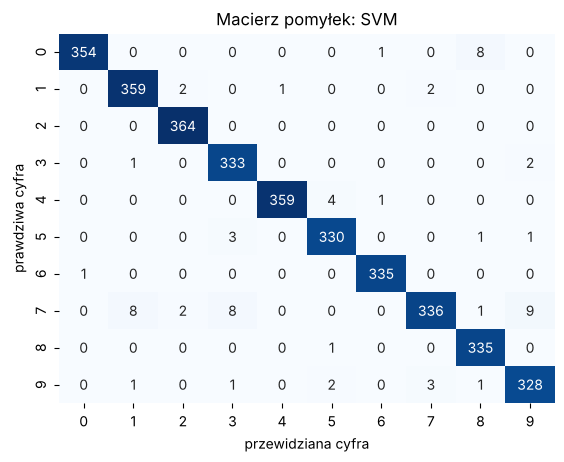

In [9]:
# C2. Błędy najlepszego modelu
najlepszy = wyniki.index[0]
print("Najlepszy model:", najlepszy)
print(classification_report(y_test, pred[najlepszy], digits=3))
sns.heatmap(confusion_matrix(y_test, pred[najlepszy]), annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("przewidziana cyfra"); plt.ylabel("prawdziwa cyfra"); plt.title(f"Macierz pomyłek: {najlepszy}")
plt.show()

In [10]:
# C3. Czy przewaga najlepszego modelu nie jest przypadkiem? (test McNemara)
# a = najlepszy ma rację, a drugi się myli; b = odwrotnie. Przy równie dobrych modelach a i b
# byłyby podobne, jak orły i reszki. binomtest liczy, jak prawdopodobny jest taki podział (p).
dobrze = pred[najlepszy] == y_test
for nazwa in wyniki.index[1:-1]:                  # pomijamy najlepszy i baseline (ostatni)
    inny = pred[nazwa] == y_test
    a, b = int((dobrze & ~inny).sum()), int((~dobrze & inny).sum())
    print(f"{najlepszy} vs {nazwa:22s} a = {a:3d}, b = {b:3d}, p = {binomtest(a, a + b).pvalue:.2g}")

SVM vs k-NN                   a =  38, b =  15, p = 0.0022
SVM vs Las losowy             a =  79, b =  20, p = 1.8e-09
SVM vs Regresja logistyczna   a = 194, b =   8, p = 1.9e-47
SVM vs Naive Bayes            a = 563, b =   7, p = 2e-156


### Wnioski
(Liczby z mojego uruchomienia. Czasy zależą od komputera, reszta wychodzi zawsze tak samo.)

1. **Wszystkie modele wyraźnie biją baseline** (10,4%). Najlepszy jest SVM: 98,1% accuracy na teście,
   65 błędów na 3498 próbek. Drugi jest k-NN (97,5%, 88 błędów), trzeci las losowy (96,5%, 124 błędy).
2. **Naive Bayes (82,3%) i regresja logistyczna (92,8%) są wyraźnie słabsze.** Ich założenia
   (niezależne cechy, liniowe granice) nie pasują do danych, w których kolejne punkty śladu pióra
   są mocno ze sobą powiązane.
3. **Błędy SVM:** najtrudniejsza jest cyfra 7 (czułość 92,3%), mylona z 9, 1 i 3. Często mylone jest
   też 0 z 8: obie cyfry zaczynają się u góry i zataczają pętlę.
4. **Walidacja według osób była potrzebna:** foldy losowe zawyżają wynik (k-NN: 99,4% zamiast 96,7%),
   bo model widzi w nauce cyfry tej samej osoby. Foldy według osób dały wyniki bliskie testowi
   (SVM: 97,8% w CV, 98,1% na teście), więc wybór modelu był wiarygodny.
5. **Przewaga SVM nie jest przypadkiem:** test McNemara daje p ≈ 0,002 względem k-NN i jeszcze mniej
   względem pozostałych. Test zakłada niezależne próbki, a cyfry jednej osoby są podobne, więc
   p-wartości są raczej zbyt optymistyczne.
6. **Koszt:** SVM zajmuje ok. 170 kB, k-NN ok. 1 MB (pamięta cały zbiór treningowy), las losowy
   ok. 25 MB i uczy się najdłużej. Regresja logistyczna zajmuje 3 kB i przewiduje kilkadziesiąt razy
   szybciej niż SVM, ale robi prawie 4 razy więcej błędów.

**Czy wzrost złożoności jest wart poprawy?** Przejście z modelu liniowego (regresja logistyczna)
na nieliniowy (SVM) tak: liczba błędów spada z 251 do 65, a SVM nadal jest mały i szybki.
Dalszy wzrost złożoności nie: las losowy jest ok. 150 razy większy od SVM, uczy się dłużej
i robi więcej błędów. Rekomenduję SVM jako najlepszy kompromis jakości i kosztu.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.

**Źródła:** opis zbioru `pendigits.names` i `pendigits-orig.names` (E. Alpaydin, F. Alimoglu, 1998),
dokumentacja scikit-learn.

**Narzędzia AI:** Claude (Anthropic), pomoc przy pisaniu kodu i wyjaśnianiu bibliotek.